In [ ]:
import os
from google.colab import drive
drive.mount("/content/drive")

if not os.path.exists("/content/fruitnet/archive (3)"):
  !unzip -n -q "/content/drive/MyDrive/fruitnet.zip" -d /content/fruitnet
if not os.path.exists("/content/data/train"):
  !rm -rf /content/data
  !python "/content/fruitnet/archive (3)/01_limpieza_y_division.py" --origen "/content/fruitnet/archive (3)" --salida /content/data
else:
  print("Carpetas train/val/test listas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carpetas train/val/test listas


In [ ]:
import os, json, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
DATA = "/content/data"
RESULTADOS = "/content/drive/MyDrive/fruit_resultados"
os.makedirs(RESULTADOS, exist_ok=True)

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or ("No hay GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def cargar(split, shuffle):
  return keras.utils.image_dataset_from_directory(os.path.join(DATA, split), image_size=IMG_SIZE, batch_size= BATCH_SIZE, label_mode="categorical", shuffle=shuffle, seed=SEMILLA)

train_ds = cargar("train", True)
val_ds = cargar("val", False)
test_ds = cargar("test", False)

class_name = train_ds.class_names
NUM_CLASES = len(class_name)
print(class_name)
with open(os.path.join(RESULTADOS, "class_names.json"), "w") as f:
  json.dump(class_name, f)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 9592 files belonging to 12 classes.
Found 2055 files belonging to 12 classes.
Found 2053 files belonging to 12 classes.
['Apple_Bad', 'Apple_Good', 'Banana_Bad', 'Banana_Good', 'Guava_Bad', 'Guava_Good', 'Lime_Bad', 'Lime_Good', 'Orange_Bad', 'Orange_Good', 'Pomegranate_Bad', 'Pomegranate_Good']


In [ ]:
def crear_modelo_base():
  return keras.Sequential([
      keras.Input(shape= IMG_SIZE + (3, )),
      layers.Rescaling(1.0 / 255),

      layers.Conv2D(32, 3, activation="relu"),
      layers.MaxPool2D(),

      layers.Conv2D(64, 3, activation="relu"),
      layers.MaxPool2D(),

      layers.Conv2D(128, 3, activation="relu"),
      layers.MaxPool2D(),

      layers.Flatten(),
      layers.Dense(128, activation="relu"),
      layers.Dense(NUM_CLASES, activation="softmax"),
  ], name="modelo_base")

modelo = crear_modelo_base()
modelo.summary()

Model: "modelo_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,170,508 (42.61 MB)

 Trainable params: 11,170,508 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
EPOCHS = 15
TASA_APRENDIZAJE = 1e-3

modelo.compile(
    optimizer= keras.optimizers.Adam(learning_rate=TASA_APRENDIZAJE),
    loss = "categorical_crossentropy",
    metrics =["accuracy"],
)

In [ ]:
inicio = time.time()
historical = modelo.fit(train_ds, validation_data = val_ds, epochs = EPOCHS)
minutos = (time.time() - inicio) /60
print(f"Tiempo de entrenamiento: {minutos:.1f} min")

Epoch 1/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 25s 73ms/step - accuracy: 0.7147 - loss: 0.8614 - val_accuracy: 0.5942 - val_loss: 1.5128
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 61ms/step - accuracy: 0.9339 - loss: 0.2229 - val_accuracy: 0.6487 - val_loss: 1.7475
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 61ms/step - accuracy: 0.9687 - loss: 0.1017 - val_accuracy: 0.6603 - val_loss: 1.9889
Epoch 4/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 61ms/step - accuracy: 0.9800 - loss: 0.0711 - val_accuracy: 0.6302 - val_loss: 2.2846
Epoch 5/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 63ms/step - accuracy: 0.9885 - loss: 0.0385 - val_accuracy: 0.6302 - val_loss: 2.6810
Epoch 6/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 61ms/step - accuracy: 0.9842 - loss: 0.0545 - val_accuracy: 0.5645 - val_loss: 3.5382
Epoch 7/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 63ms/step - accuracy: 0.9832 - loss: 0.0563 - val_accuracy: 0.6287 - val_loss: 3.1863
Epoch 8/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 63ms/step - accuracy: 0.9937 - loss: 0.0212 - 

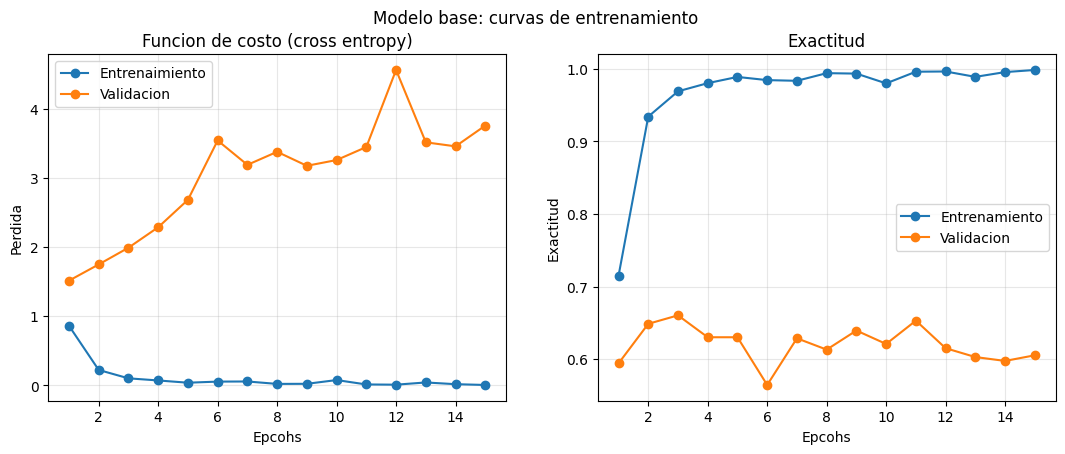

Epochs con menor perdida de validacion: 1
 ( val_loss = 1.513, val_acc = 0.594)
Ultima epoch: train_acc =0.998, val_acc =0.605
 brecha = 0.393


In [ ]:
h = historical.history
ep = range(1, len(h["loss"]) +1)

fig, axes = plt.subplots(1,2, figsize=(13,4.5))
axes[0].plot(ep, h["loss"], "o-", label="Entrenaimiento")
axes[0].plot(ep,h["val_loss"], "o-", label = "Validacion")
axes[0].set_title("Funcion de costo (cross entropy)"); axes[0].set_xlabel("Epcohs"); axes[0].set_ylabel('Perdida')

axes[1].plot(ep, h["accuracy"], "o-", label="Entrenamiento")
axes[1].plot(ep, h["val_accuracy"], "o-", label="Validacion")
axes[1].set_title("Exactitud"); axes[1].set_xlabel("Epcohs"); axes[1].set_ylabel('Exactitud')


for ax in axes:
  ax.legend(); ax.grid(alpha=0.3)
plt.suptitle("Modelo base: curvas de entrenamiento")
plt.show()

mejor = int(np.argmin(h['val_loss']))
print(f"Epochs con menor perdida de validacion: {mejor + 1}"
f"\n ( val_loss = {h['val_loss'][mejor]:.3f}, val_acc = {h['val_accuracy'][mejor]:.3f})")

print(f"Ultima epoch: train_acc ={h['accuracy'][-1]:.3f}, val_acc ={h['val_accuracy'][-1]:.3f}"
f"\n brecha = {h['accuracy'][-1] - h['val_accuracy'][-1]:.3f}")


In [ ]:
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in val_ds])
probs= modelo.predict(val_ds, verbose=0)
y_pred = np.argmax(probs, axis=1)

val_loss, val_acc = modelo.evaluate(val_ds, verbose=0)
print(f"Validacion: perdida = {val_loss:.3f}, Exactitud = {val_acc:.3f}\n")
print(classification_report(y_true, y_pred, target_names=class_name, digits=3, zero_division=0))

Validacion: perdida = 3.754, Exactitud = 0.605

                  precision    recall  f1-score   support

       Apple_Bad      0.644     0.550     0.593       171
      Apple_Good      0.480     0.751     0.586       173
      Banana_Bad      0.764     0.515     0.615       163
     Banana_Good      0.796     0.681     0.734       166
       Guava_Bad      0.607     0.639     0.622       169
      Guava_Good      0.517     0.705     0.597       173
        Lime_Bad      0.550     0.577     0.563       163
       Lime_Good      0.889     0.393     0.545       163
      Orange_Bad      0.547     0.400     0.462       175
     Orange_Good      0.443     0.514     0.476       183
 Pomegranate_Bad      0.723     0.601     0.656       178
Pomegranate_Good      0.680     0.921     0.783       178

        accuracy                          0.605      2055
       macro avg      0.637     0.604     0.603      2055
    weighted avg      0.634     0.605     0.602      2055



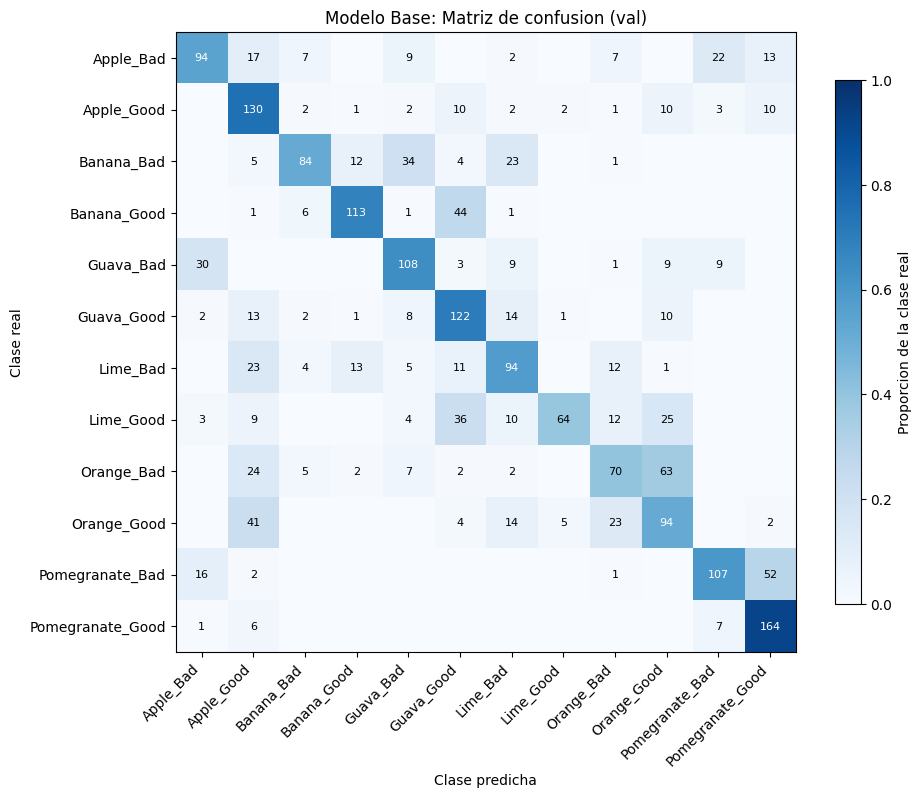

Confusiones mas frecuentas: (real, predicha)
        Orange_Bad, Orange_Good       63
   Pomegranate_Bad, Pomegranate_Good  52
       Banana_Good, Guava_Good        44
       Orange_Good, Apple_Good        41
         Lime_Good, Guava_Good        36
        Banana_Bad, Guava_Bad         34
         Guava_Bad, Apple_Bad         30
         Lime_Good, Orange_Good       25

 Errores totales: 811 | de fruta 610 | solo de calidad: 201


In [ ]:
def graficar_matriz(y_true, y_pred, titulo):
  cm = confusion_matrix(y_true, y_pred)
  cm_norm = cm /cm.sum(axis=1, keepdims=True)
  fig, ax = plt.subplots(figsize=(10,8.5))
  im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
  ax.set_xticks(range(NUM_CLASES)); ax.set_xticklabels(class_name, rotation =45, ha="right")
  ax.set_yticks(range(NUM_CLASES)); ax.set_yticklabels(class_name)
  for i in range(NUM_CLASES):
    for j in range(NUM_CLASES):
      if cm[i, j]:
        ax.text(j,i, cm[i,j], ha="center", va="center", fontsize=8, color="white" if cm_norm[i,j] > 0.5 else "black")
  ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real"); ax.set_title(titulo)
  plt.colorbar(im, ax=ax, shrink =0.8, label="Proporcion de la clase real")
  plt.show()
  return cm

cm = graficar_matriz(y_true, y_pred, "Modelo Base: Matriz de confusion (val)")

errores = [(cm[i, j], class_name[i], class_name[j]) for i in range(NUM_CLASES) for j in range(NUM_CLASES) if i != j and cm [i, j] >0]
print("Confusiones mas frecuentas: (real, predicha)")
for n, real, pred in sorted(errores, reverse=True)[:8]:
  print(f" {real:>17}, {pred:<17} {n}")
fruta = lambda k: class_name[k].split("_")[0]
mal= y_true != y_pred
err_fruta = sum(fruta(a) != fruta(b) for a, b in zip(y_true[mal], y_pred[mal]))
print(f"\n Errores totales: {mal.sum()} | de fruta {err_fruta} | solo de calidad: {mal.sum() - err_fruta}")

In [ ]:
modelo.save(os.path.join(RESULTADOS, "modelo_base.keras"))

resultado ={
    "modelo": "Modelo base CNN",
    "parametros": int(modelo.count_params()),
    "epochs": len(h["loss"]),
    "minutos": round(minutos,1),
    "train_acc": round(float(h["accuracy"][-1]), 4),
    "val_acc": round(float(val_acc), 4),
    "val_loss": round(float(val_loss), 4),
    "historical": {k: [round(float(v), 4) for v in vals] for k, vals in h.items()},
}
with open(os.path.join(RESULTADOS, "resultado_modelo_base.json"), "w") as f:
  json.dump(resultado, f, indent=2)
print(json.dumps({k: v for k, v in resultado.items() if k != "historical"}, indent = 2, ensure_ascii=False))

{
  "modelo": "Modelo base CNN",
  "parametros": 11170508,
  "epochs": 15,
  "minutos": 4.8,
  "train_acc": 0.9981,
  "val_acc": 0.6054,
  "val_loss": 3.7538
}
